<a href="https://colab.research.google.com/github/fhs8426004/i2wi-learning-fhs8426004/blob/main/unit40.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix

# 図の色を先に決めておく（BLUE=主役、ORANGE=強調・注意、INK=文字と基準線、MUTED=補助）。以降の図で同じ意味に使う
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#898781"
# 図の見た目をまとめて設定（解像度、上と右の枠線を消す、薄い罫線）。内容には関係しない
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.grid": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
})

# 前の回（ユニット16）と同じデータ・同じ分け方・同じ選び方を、もう一度作る。値は前の回と同じになる（乱数の種も、前の回と同じ）
raw = load_breast_cancer(as_frame=True)
X = raw.data                                  # 特徴量 30 個（表）
y = (raw.target == 0).astype(int)             # 悪性 = 1、良性 = 0 にそろえる（前の回と同じ）
names = list(X.columns)
# テスト用 20% を最初に取り分けて、封をする（前の回の 6 節。20% は人が決めた値、random_state=0）
Xdev, Xte, ydev, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
# モデルは「標準化 → ロジスティック回帰」（前の回の 6 節）。max_iter=1000 は、収束の打ち切り回数で、人が決めた値
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)   # 5 分割。5 は人が決めた値（前の回の 6 節）
# 前の回の 7 節で選んだ C を、同じ方法で選び直す（開発用の中の交差検証。テスト用は使わない）
grid = GridSearchCV(lr, {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]},   # 10 倍刻みの 6 点（人が決めた範囲）
                    cv=cv5, scoring="roc_auc").fit(Xdev, ydev)
print("開発用:", len(ydev), "／ テスト用（封をしている）:", len(yte))
print("選ばれた C:", grid.best_params_["logisticregression__C"], "／ 検証の AUC =", round(grid.best_score_, 4))

開発用: 455 ／ テスト用（封をしている）: 114
選ばれた C: 0.1 ／ 検証の AUC = 0.9944


In [2]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn import metrics as skm

# 検証用の予測: 開発用 455 例を 5 分割し、各例を「その例を含まない 4/5 で学習したモデル」で予測する（out-of-fold）。テスト用は使わない
oof = cross_val_predict(clone(grid.best_estimator_), Xdev, ydev, cv=cv5, method="predict_proba")[:, 1]
pred_v = (oof >= 0.5).astype(int)                      # しきい値 0.5。人が決めた値
tn, fp, fn, tp = confusion_matrix(ydev, pred_v).ravel()
print("TN, FP, FN, TP =", tn, fp, fn, tp)
own = {"accuracy": (tp + tn) / (tp + tn + fp + fn), "sensitivity (recall)": tp / (tp + fn), "specificity": tn / (tn + fp),
       "precision (PPV)": tp / (tp + fp), "NPV": tn / (tn + fn)}
own["F1"] = 2 * own["precision (PPV)"] * own["sensitivity (recall)"] / (own["precision (PPV)"] + own["sensitivity (recall)"])
own["balanced accuracy"] = (own["sensitivity (recall)"] + own["specificity"]) / 2
lib = {"accuracy": skm.accuracy_score(ydev, pred_v), "sensitivity (recall)": skm.recall_score(ydev, pred_v),
       "specificity": skm.recall_score(ydev, pred_v, pos_label=0),          # 良性（0）を「陽性」とみなした再現率 = 特異度
       "precision (PPV)": skm.precision_score(ydev, pred_v), "NPV": skm.precision_score(ydev, pred_v, pos_label=0),
       "F1": skm.f1_score(ydev, pred_v), "balanced accuracy": skm.balanced_accuracy_score(ydev, pred_v)}
print(pd.DataFrame({"own formula": own, "scikit-learn": lib}).round(4).to_string())
print("最大の差:", max(abs(own[k] - lib[k]) for k in own))

# 負例: 「全部良性」と答える分類器。正解率はいくつで、感度はいくつか
zero = np.zeros(len(ydev), dtype=int)
print(f"全部良性: 正解率 {skm.accuracy_score(ydev, zero):.3f}、感度 {skm.recall_score(ydev, zero):.3f}")

TN, FP, FN, TP = 284 1 9 161
                      own formula  scikit-learn
accuracy                   0.9780        0.9780
sensitivity (recall)       0.9471        0.9471
specificity                0.9965        0.9965
precision (PPV)            0.9938        0.9938
NPV                        0.9693        0.9693
F1                         0.9699        0.9699
balanced accuracy          0.9718        0.9718
最大の差: 0.0
全部良性: 正解率 0.626、感度 0.000


In [4]:
sens_v, spec_v = own["sensitivity (recall)"], own["specificity"]
ben, mal = np.where(ydev == 0)[0], np.where(ydev == 1)[0]          # 良性・悪性の行の番号
rows = []
for p in [ydev.mean(), 0.05, 0.01]:                                  # 有病率: このデータの値、5%、1%。5% と 1% は人が決めた値（健診や検診の有病率を想像した例。実際の値ではない）
    ppv_formula = sens_v * p / (sens_v * p + (1 - spec_v) * (1 - p))
    n_mal = int(round(p / (1 - p) * len(ben)))                       # 良性 285 例はそのまま、悪性を p になるまで間引く
    sim = []
    for seed in range(60):                                           # 60 通り。人が決めた値（悪性を間引く例の選び方で、値が揺れるため）
        idx = np.r_[ben, np.random.default_rng(seed).choice(mal, n_mal, replace=False)]
        sim.append(skm.precision_score(ydev.iloc[idx], pred_v[idx], zero_division=0))
    rows.append((f"{p:.3f}", n_mal, round(ppv_formula, 3), round(float(np.mean(sim)), 3), round(1 - p, 3)))
print(pd.DataFrame(rows, columns=["prevalence", "malignant n", "PPV (formula)", "PPV (simulated)", "accuracy of 'all benign'"]).to_string(index=False))

prevalence  malignant n  PPV (formula)  PPV (simulated)  accuracy of 'all benign'
     0.374          170          0.994            0.994                     0.626
     0.050           15          0.934            0.934                     0.950
     0.010            3          0.732            0.740                     0.990


全データ（悪性 37%）: ROC-AUC 0.9946、AP 0.9933、Brier 0.0250（scikit-learn: 0.0250）
悪性 5%（15 例）: ROC-AUC 0.9926、AP 0.9648（60 通りの平均）
悪性 1%（3 例）: ROC-AUC 0.9939、AP 0.9580（60 通りの平均）


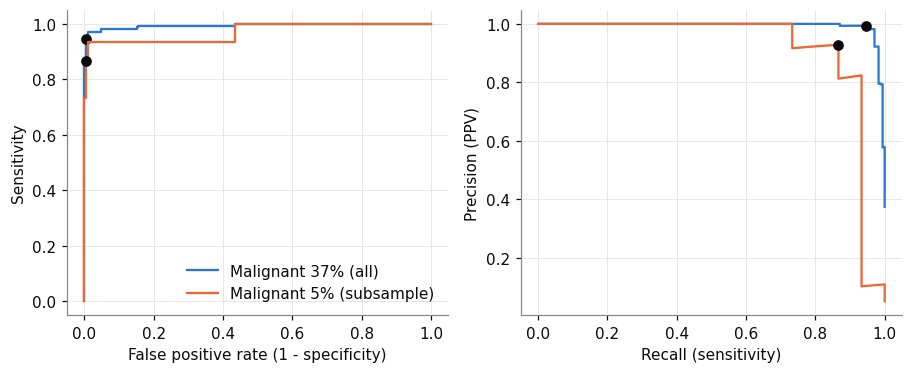

In [5]:
roc_full, ap_full = skm.roc_auc_score(ydev, oof), skm.average_precision_score(ydev, oof)
brier_own = np.mean((oof - ydev.values) ** 2)                                      # Brier = (確率 − 本当の 0/1) の二乗の平均
print(f"全データ（悪性 37%）: ROC-AUC {roc_full:.4f}、AP {ap_full:.4f}、Brier {brier_own:.4f}（scikit-learn: {skm.brier_score_loss(ydev, oof):.4f}）")
for p in [0.05, 0.01]:                                                              # 悪性を間引いた有病率（上と同じ値）
    n_mal = int(round(p / (1 - p) * len(ben)))
    r, a = [], []
    for seed in range(60):
        idx = np.r_[ben, np.random.default_rng(seed).choice(mal, n_mal, replace=False)]
        r.append(skm.roc_auc_score(ydev.iloc[idx], oof[idx])); a.append(skm.average_precision_score(ydev.iloc[idx], oof[idx]))
    print(f"悪性 {p:.0%}（{n_mal} 例）: ROC-AUC {np.mean(r):.4f}、AP {np.mean(a):.4f}（60 通りの平均）")

# 図の読み方: 左は ROC 曲線（横軸 = 偽陽性率、縦軸 = 感度）。右は PR 曲線（横軸 = 再現率、縦軸 = 適合率）。
# 青 = 全データ、オレンジ = 悪性を 5% に間引いたもの（乱数の種 0 の 1 回）。黒の点は、しきい値 0.5 の位置。
# ROC は、2 本がほぼ重なる。PR は、オレンジが全体に下がる（有病率が下がると、適合率が下がるため）。
idx5 = np.r_[ben, np.random.default_rng(0).choice(mal, int(round(0.05 / 0.95 * len(ben))), replace=False)]
fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.5))
for yy_, pp_, col, lab in [(ydev.values, oof, BLUE, "Malignant 37% (all)"), (ydev.values[idx5], oof[idx5], ORANGE, "Malignant 5% (subsample)")]:
    fpr, tpr, _ = skm.roc_curve(yy_, pp_); pr_, rc_, _ = skm.precision_recall_curve(yy_, pp_)
    axs[0].plot(fpr, tpr, color=col, label=lab); axs[1].plot(rc_, pr_, color=col, label=lab)
    tn_, fp_, fn_, tp_ = confusion_matrix(yy_, (pp_ >= 0.5).astype(int)).ravel()     # しきい値 0.5 の混同行列
    axs[0].plot(fp_ / (fp_ + tn_), tp_ / (tp_ + fn_), "o", color=INK)                   # ROC 上の点: (偽陽性率, 感度)
    axs[1].plot(tp_ / (tp_ + fn_), tp_ / (tp_ + fp_), "o", color=INK)                   # PR 上の点: (再現率, 適合率)
axs[0].set_xlabel("False positive rate (1 - specificity)"); axs[0].set_ylabel("Sensitivity"); axs[0].legend(frameon=False, loc="lower right")
axs[1].set_xlabel("Recall (sensitivity)"); axs[1].set_ylabel("Precision (PPV)")
plt.tight_layout(); plt.show()

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

def r2_own(y_true, y_pred):
    """決定係数 = 1 − 残差平方和 ÷ 全平方和（全平方和 = 平均で予測したときの平方和）"""
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)

target = "mean area"
Xa, Xb, ya, yb = train_test_split(Xdev, Xdev[target], test_size=0.3, random_state=0)       # 訓練 70%／検証 30%。0.3 と乱数の種 0 は人が決めた値
f_all = [c for c in names if c != target]                                                  # 面積そのもの以外の 29 特徴量
f_weak = ["mean texture", "mean smoothness", "mean symmetry"]                              # 面積と関係の薄そうな 3 つ（人が選んだ。関係の強さは確かめていない）
models_r = {"predict the training mean": None,
            "linear: radius only": (LinearRegression(), ["mean radius"]),
            "linear: texture+smoothness+symmetry": (LinearRegression(), f_weak),
            "linear: all 29": (LinearRegression(), f_all),
            "decision tree: all 29": (DecisionTreeRegressor(random_state=0), f_all)}
rows = []
for name, spec_ in models_r.items():
    if spec_ is None:
        p_tr, p_va = np.full(len(ya), ya.mean()), np.full(len(yb), ya.mean())             # 平均で予測（訓練の平均を、検証にも使う）
    else:
        m, cols = spec_; m.fit(Xa[cols], ya); p_tr, p_va = m.predict(Xa[cols]), m.predict(Xb[cols])
    assert np.isclose(r2_own(yb.values, p_va), skm.r2_score(yb, p_va))                       # 自分の式と scikit-learn が一致することを確かめる
    rows.append((name, r2_own(ya.values, p_tr), r2_own(yb.values, p_va), skm.mean_absolute_error(yb, p_va), np.sqrt(np.mean((yb.values - p_va) ** 2))))
print(pd.DataFrame(rows, columns=["model", "R2 (train)", "R2 (validation)", "MAE", "RMSE"]).round(3).to_string(index=False))
print("検証の面積の平均:", round(yb.mean(), 1))
# R² と r²（相関係数の 2 乗）は別物: 予測を、正解の 0.5 倍にしてしまった場合
half = 0.5 * yb.values
print(f"予測 = 正解 × 0.5: r² = {np.corrcoef(yb.values, half)[0, 1] ** 2:.3f}、R² = {r2_own(yb.values, half):.3f}")

                              model  R2 (train)  R2 (validation)     MAE    RMSE
          predict the training mean       0.000           -0.022 271.995 376.352
                linear: radius only       0.974            0.972  40.841  62.631
linear: texture+smoothness+symmetry       0.147            0.126 248.112 348.102
                     linear: all 29       0.998            0.992  15.092  33.679
              decision tree: all 29       1.000            0.966  21.174  68.824
検証の面積の平均: 690.7
予測 = 正解 × 0.5: r² = 1.000、R² = -0.111


In [8]:
yy_g, xx_g = np.ogrid[:128, :128]                                         # 128×128 画素の画像（128 は人が決めた値）
def disk(r, dy=0):
    """中心 (64, 64) から dy 画素だけ下へずらした、半径 r の円（True = 領域）"""
    return (yy_g - 64 - dy) ** 2 + (xx_g - 64) ** 2 <= r * r

def dice(a, b):
    """Dice = 2 × 重なり ÷ 両方の画素数の和（第5回ユニット37 と同じ式）。両方が空なら 0÷0 で定義できないので nan を返す"""
    s = a.sum() + b.sum()
    return np.nan if s == 0 else 2 * np.logical_and(a, b).sum() / s

def iou(a, b):
    u = np.logical_or(a, b).sum()
    return np.nan if u == 0 else np.logical_and(a, b).sum() / u

rows = []
for r in (3, 30):                                                         # 小さな領域と大きな領域。3 と 30 は人が決めた値
    a, b = disk(r), disk(r, 1)                                            # 正解と、1 画素だけずれた予測
    d, i = dice(a, b), iou(a, b)
    rows.append((r, int(a.sum()), round(d, 4), round(i, 4), round(2 * i / (1 + i), 4), round(skm.f1_score(a.ravel(), b.ravel()), 4)))
print(pd.DataFrame(rows, columns=["radius", "pixels", "Dice", "IoU", "2*IoU/(1+IoU)", "F1 (pixelwise)"]).to_string(index=False))

# 負例: 何も塗らない予測。画素の正解率と Dice を比べる。両方が空のときの扱いも見る
a, empty = disk(3), np.zeros((128, 128), dtype=bool)
print(f"何も塗らない: 画素の正解率 {(a == empty).mean():.4f}、Dice {dice(a, empty):.1f}")
print("正解も予測も空: Dice =", dice(empty, empty), "（0÷0。1 とみなすか、評価から外すかを、研究の前に決めて書く）")

 radius  pixels   Dice    IoU  2*IoU/(1+IoU)  F1 (pixelwise)
      3      29 0.7586 0.6111         0.7586          0.7586
     30    2821 0.9784 0.9577         0.9784          0.9784
何も塗らない: 画素の正解率 0.9982、Dice 0.0
正解も予測も空: Dice = nan （0÷0。1 とみなすか、評価から外すかを、研究の前に決めて書く）


In [9]:
# 同じ混同行列（8-1 の tn, fp, fn, tp）から、統計の式と、機械学習の関数を、それぞれ計算して並べる
n_ = tn + fp + fn + tp
prev = (tp + fn) / n_                                                       # このデータの有病率（悪性の割合）
sens, spec = tp / (tp + fn), tn / (tn + fp)
fpr_r, tpr_r, thr_r = skm.roc_curve(ydev, oof, drop_intermediate=False)    # ROC 曲線の全点（点を間引かない）
k = np.flatnonzero(thr_r >= 0.5)[-1]                                       # しきい値 0.5 以上で、いちばん低い点（pred_v の作り方と同じ）
A, B = ydev.values == 1, pred_v == 1                                       # 正解が悪性の例の集合 A と、悪性と言った例の集合 B
rows = [
    ("sensitivity = recall = TPR",   sens,                                                      skm.recall_score(ydev, pred_v)),
    ("TPR (roc_curve)",              sens,                                                      tpr_r[k]),
    ("specificity",                  spec,                                                      skm.recall_score(ydev, pred_v, pos_label=0)),
    ("FPR = 1 - specificity",        1 - spec,                                                  fpr_r[k]),
    ("PPV (Bayes, data prevalence)", sens * prev / (sens * prev + (1 - spec) * (1 - prev)),     skm.precision_score(ydev, pred_v)),
    ("NPV (Bayes, data prevalence)", spec * (1 - prev) / (spec * (1 - prev) + (1 - sens) * prev), skm.precision_score(ydev, pred_v, pos_label=0)),
    ("FDR = 1 - PPV",                1 - tp / (tp + fp),                                        fp / (tp + fp)),
    ("F1",                           2 * tp / (2 * tp + fp + fn),                               skm.f1_score(ydev, pred_v)),
    ("Dice of the two sets",         2 * (A & B).sum() / (A.sum() + B.sum()),                   skm.f1_score(ydev, pred_v)),
    ("Jaccard = IoU",                tp / (tp + fp + fn),                                       skm.jaccard_score(ydev, pred_v)),
    ("balanced accuracy",            (sens + spec) / 2,                                         skm.balanced_accuracy_score(ydev, pred_v)),
    ("LR+ = sens / (1 - spec)",      sens / (1 - spec),                                         skm.class_likelihood_ratios(ydev, pred_v)[0]),
]
tab = pd.DataFrame(rows, columns=["term", "statistics-style formula", "machine-learning function"])
tab["difference"] = (tab.iloc[:, 1] - tab.iloc[:, 2]).abs()
print(tab.round(4).to_string(index=False))
assert tab["difference"].max() < 1e-12, "名前が違う指標が、同じ値になっていません"                  # 確かめ（正例）: 12 組が一致する

# 負例 1: 「適合率 = PPV」は、有病率が同じときだけ。有病率 1% の場面の PPV は、同じ感度・特異度でも、この適合率とは別の値になる
ppv_1 = sens * 0.01 / (sens * 0.01 + (1 - spec) * 0.99)                    # 0.01 は、検診を想定して人が決めた値
print(f"有病率 {prev:.3f}（このデータ）: PPV = precision = {skm.precision_score(ydev, pred_v):.4f}／有病率 0.010 の場面の PPV = {ppv_1:.4f}（感度 {sens:.4f}・特異度 {spec:.4f} は同じ）")
assert abs(ppv_1 - skm.precision_score(ydev, pred_v)) > 0.2
# 負例 2: `recall_score` の既定値は感度。特異度ではない（pos_label=0 を付け忘れると、特異度のつもりで感度が出る）
print("recall_score(既定) =", round(skm.recall_score(ydev, pred_v), 4), "／ 特異度 =", round(spec, 4))
assert abs(skm.recall_score(ydev, pred_v) - spec) > 0.04

                        term  statistics-style formula  machine-learning function  difference
  sensitivity = recall = TPR                    0.9471                     0.9471         0.0
             TPR (roc_curve)                    0.9471                     0.9471         0.0
                 specificity                    0.9965                     0.9965         0.0
       FPR = 1 - specificity                    0.0035                     0.0035         0.0
PPV (Bayes, data prevalence)                    0.9938                     0.9938         0.0
NPV (Bayes, data prevalence)                    0.9693                     0.9693         0.0
               FDR = 1 - PPV                    0.0062                     0.0062         0.0
                          F1                    0.9699                     0.9699         0.0
        Dice of the two sets                    0.9699                     0.9699         0.0
               Jaccard = IoU                    0.9415      

In [10]:
from sklearn.model_selection import LeaveOneOut, LeaveOneGroupOut, KFold, GroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
import time

est = clone(grid.best_estimator_)
t0 = time.time(); p_loo = cross_val_predict(est, Xdev, ydev, cv=LeaveOneOut(), method="predict_proba")[:, 1]; t_loo = time.time() - t0   # 455 回学習する
t0 = time.time(); p_5 = cross_val_predict(est, Xdev, ydev, cv=cv5, method="predict_proba")[:, 1]; t_5 = time.time() - t0                  # 5 回学習する
aucs5 = [roc_auc_score(ydev, cross_val_predict(est, Xdev, ydev, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="predict_proba")[:, 1])
         for s in range(20)]                                                                    # 分け方を 20 通り（乱数の種 0〜19。20 は人が決めた値）
print(f"LOO:    AUC = {roc_auc_score(ydev, p_loo):.4f}（学習 {len(ydev)} 回、{t_loo:.1f} 秒。LOO は決まった分け方なので、揺れない）")
print(f"5 分割: AUC = {roc_auc_score(ydev, p_5):.4f}（学習 5 回、{t_5:.2f} 秒）／ 分け方 20 通り: 平均 {np.mean(aucs5):.4f}、標準偏差 {np.std(aucs5, ddof=1):.4f}、範囲 {min(aucs5):.4f}〜{max(aucs5):.4f}")

# 負例: 多数派を答えるだけのモデル（悪性 100 例・良性 100 例の、ちょうど半々のデータ）。LOO では、抜いた 1 例の「反対」が多数派になるので、必ず外れる
idx = np.r_[np.flatnonzero(ydev.values == 1)[:100], np.flatnonzero(ydev.values == 0)[:100]]    # 100 例ずつ。100 は人が決めた値
Xb, yb_ = Xdev.iloc[idx], ydev.iloc[idx]
dm = DummyClassifier(strategy="most_frequent")
acc_loo = (cross_val_predict(dm, Xb, yb_, cv=LeaveOneOut()) == yb_.values).mean()
acc_5 = (cross_val_predict(dm, Xb, yb_, cv=StratifiedKFold(5, shuffle=True, random_state=0)) == yb_.values).mean()
print(f"多数派を答えるだけのモデルの正解率（悪性 100・良性 100）: LOO = {acc_loo:.3f}、5 分割（層別化）= {acc_5:.3f}")

LOO:    AUC = 0.9947（学習 455 回、10.4 秒。LOO は決まった分け方なので、揺れない）
5 分割: AUC = 0.9946（学習 5 回、0.20 秒）／ 分け方 20 通り: 平均 0.9944、標準偏差 0.0007、範囲 0.9927〜0.9954
多数派を答えるだけのモデルの正解率（悪性 100・良性 100）: LOO = 0.000、5 分割（層別化）= 0.500


In [11]:
rg = np.random.default_rng(0)                                                 # 乱数の種 0 は人が決めた値
weak = ["mean texture", "mean smoothness", "mean symmetry", "mean fractal dimension", "texture error"]
pat = rg.choice(len(Xdev), 60, replace=False)                                  # 「患者」60 人（60 は人が決めた値）
base = Xdev.iloc[pat][weak].reset_index(drop=True); y_pat = ydev.iloc[pat].reset_index(drop=True)
sd_ = Xdev[weak].std().values
rows_, grp, yl = [], [], []
for i in range(len(base)):
    for _ in range(3):                                                         # 1 人に病変を 3 つ
        rows_.append(base.iloc[i].values + rg.normal(0, 0.05 * sd_)); grp.append(i); yl.append(y_pat.iloc[i])
XL, gL, yL = pd.DataFrame(rows_, columns=weak), np.array(grp), np.array(yl)
m1 = make_pipeline(StandardScaler(), KNeighborsClassifier(1))                 # 最近傍法（k-nearest neighbors, k-NN）で k = 1。似た例の答えを、そのまま写す（覚えるモデル）
print("病変:", len(yL), "例 ／ 患者:", len(set(gL)), "人 ／ 悪性の患者の割合:", round(y_pat.mean(), 2))

# 検査（正例）: LOGO では、検証に出した群が、訓練に 1 例も入らない。（負例）: LOO では、検証に出した病変の患者が、訓練に残っている
assert all(set(gL[tr]).isdisjoint(gL[te]) for tr, te in LeaveOneGroupOut().split(XL, yL, gL))
assert all(len(set(gL[tr]) & set(gL[te])) == 1 for tr, te in LeaveOneOut().split(XL))

def acc_(cv, **kw):
    return (cross_val_predict(m1, XL, yL, cv=cv, **kw) == yL).mean()
res = {"LOO (one lesion out)": acc_(LeaveOneOut()),
       "5-fold KFold (lesions)": acc_(KFold(5, shuffle=True, random_state=0)),
       "LOGO (one patient out)": acc_(LeaveOneGroupOut(), groups=gL),
       "GroupKFold 5 (patients)": acc_(GroupKFold(5), groups=gL)}
for k_, v_ in res.items(): print(f"{k_:26s} 正解率 {v_:.3f}")
# 基準: 患者 1 人につき病変 1 つだけのデータ（60 例）を LOO で測る。同じ患者の例が混ざらないので、素直な値になる
one = (cross_val_predict(m1, base, y_pat, cv=LeaveOneOut()) == y_pat.values).mean()
print(f"{'基準: 1 人 1 病変の LOO':26s} 正解率 {one:.3f}")

病変: 180 例 ／ 患者: 60 人 ／ 悪性の患者の割合: 0.4
LOO (one lesion out)       正解率 1.000
5-fold KFold (lesions)     正解率 0.972
LOGO (one patient out)     正解率 0.772
GroupKFold 5 (patients)    正解率 0.722
基準: 1 人 1 病変の LOO          正解率 0.800


In [12]:
p = 0.02
print(sens_v * p / (sens_v * p + (1 - spec_v) * (1 - p)))

0.8463524854744993


In [13]:
a = disk(5)
print(dice(a, disk(5, 1)), dice(a, disk(5, 3)))

0.8641975308641975 0.6419753086419753


In [14]:
print(round(skm.average_precision_score(ydev, pred_v), 4))

0.961


In [16]:
n, p, rec, prec = 455, 0.374, 0.947, 0.994
tp_ = rec * n * p                  # 161.15
fp_ = tp_ * (1 / prec - 1)         # 0.97（適合率 = TP ÷ (TP+FP) より、FP = TP × (1 ÷ 適合率 − 1)）
tn_ = n * (1 - p) - fp_            # 283.86（良性の数 − FP）
print(round(tn_ / (tn_ + fp_), 4))

0.9966


In [17]:
final = grid.best_estimator_                              # 検証で選んだ C で、開発用の全部（455 例）で学習し直したもの（GridSearchCV の既定動作）
prob = final.predict_proba(Xte)[:, 1]                     # 悪性の確率
pred = (prob >= 0.5).astype(int)                          # しきい値 0.5。人が決めた値（臨床の目的で動かす。この講義の範囲では 0.5 のまま）
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["true benign", "true malignant"], columns=["pred benign", "pred malignant"]))
sens, spec = tp / (tp + fn), tn / (tn + fp)               # 感度 = 悪性を悪性と言えた割合、特異度 = 良性を良性と言えた割合
print(f"感度 {sens:.3f}（{tp}/{tp + fn}）／ 特異度 {spec:.3f}（{tn}/{tn + fp}）／ AUC {roc_auc_score(yte, prob):.4f}")

# 不確かさ。比率は Wilson の区間、AUC はテスト用の 114 例を重複を許して選び直す（ブートストラップ）区間
for lab, k, n_ in [("感度", tp, tp + fn), ("特異度", tn, tn + fp)]:
    ci = stats.binomtest(int(k), int(n_)).proportion_ci(confidence_level=0.95, method="wilson")
    print(f"{lab} の 95% 信頼区間（Wilson）: {ci.low:.3f}〜{ci.high:.3f}")
rng = np.random.default_rng(0)                            # 乱数の種。0 は人が決めた値
aucs = []
for _ in range(2000):                                     # 2000 回。人が決めた値（区間の端が安定すれば十分）
    i = rng.integers(0, len(yte), len(yte))
    if yte.iloc[i].nunique() == 2: aucs.append(roc_auc_score(yte.iloc[i], prob[i]))
print(f"AUC の 95% 信頼区間（ブートストラップ）: {np.percentile(aucs, 2.5):.3f}〜{np.percentile(aucs, 97.5):.3f}")

                pred benign  pred malignant
true benign              71               1
true malignant            2              40
感度 0.952（40/42）／ 特異度 0.986（71/72）／ AUC 0.9917
感度 の 95% 信頼区間（Wilson）: 0.842〜0.987
特異度 の 95% 信頼区間（Wilson）: 0.925〜0.998
AUC の 95% 信頼区間（ブートストラップ）: 0.979〜1.000


In [18]:
rng = np.random.default_rng(0)                            # 乱数の種。0 は人が決めた値
best = []
for _ in range(60):                                       # 60 回くり返す。人が決めた値
    t = rng.integers(0, 2, 114)                           # テスト用の本当のラベル（114 例。悪性の割合は半々）
    accs = [(rng.integers(0, 2, 114) == t).mean() for _ in range(20)]    # 当てずっぽうの分類器 20 個の正解率
    best.append(max(accs))                                # 「一番良かった」ものを報告した場合の値
print(f"当てずっぽうの本当の正解率: 0.50 ／ 20 個から一番良いものを選んだ正解率: 平均 {np.mean(best):.3f}（最小 {min(best):.3f}、最大 {max(best):.3f}）")

当てずっぽうの本当の正解率: 0.50 ／ 20 個から一番良いものを選んだ正解率: 平均 0.588（最小 0.544、最大 0.675）


In [19]:
print(round(roc_auc_score(yte, final.predict(Xte)), 4))

0.9692


 depth  training  validation
     1     0.923       0.899
     2     0.952       0.921
     3     0.976       0.932
     4     0.991       0.932
     5     0.996       0.934
     6     0.998       0.930
     8     1.000       0.927
    10     1.000       0.927
    12     1.000       0.927


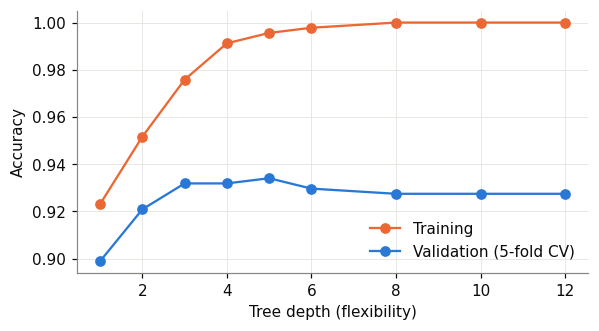

In [20]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12]
tr, va = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=0)
    tr.append(t.fit(Xdev, ydev).score(Xdev, ydev))                       # 訓練に使ったデータでの正解率
    va.append(cross_val_score(t, Xdev, ydev, cv=cv5).mean())             # 見ていないデータでの正解率（交差検証）
print(pd.DataFrame({"depth": depths, "training": np.round(tr, 3), "validation": np.round(va, 3)}).to_string(index=False))
# 図の読み方: 横軸は木の深さ（柔軟さ）。オレンジは訓練データでの正解率、青は見ていないデータ（検証）での正解率。
# 深くなるほどオレンジは 1.0 に近づく（覚える）が、青は上がらない。2 本の間の差が、過学習。
fig, ax = plt.subplots(figsize=(6, 3.1))
ax.plot(depths, tr, "o-", color=ORANGE, label="Training"); ax.plot(depths, va, "o-", color=BLUE, label="Validation (5-fold CV)")
ax.set_xlabel("Tree depth (flexibility)"); ax.set_ylabel("Accuracy"); ax.legend(frameon=False)
plt.show()